# Part A

In [7]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt

DATA_SEED = 42        # decides which 500 images we pick and the 400/100 split
SEEDS = [0, 1, 2]     # one training run per seed
SHIFT_SEED = 1234     # decides the random corruptions on shifted_test
if torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"
print("using", device)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

using cpu


In [2]:
train_set = torchvision.datasets.CIFAR10("./data", train=True, download=True)
test_set = torchvision.datasets.CIFAR10("./data", train=False, download=True)

def to_tensor(arr):
    # numpy (N, 32, 32, 3) uint8  ->  torch (N, 3, 32, 32) floats in [0, 1]
    t = torch.from_numpy(arr)
    t = t.permute(0, 3, 1, 2)
    return t.float() / 255

all_labels = np.array(train_set.targets)
rng = np.random.RandomState(DATA_SEED)

train_idx = []
val_idx = []
for c in range(10):
    class_idx = np.where(all_labels == c)[0]
    picked = rng.choice(class_idx, 50, replace=False)   # 50 images of this class
    train_idx.extend(picked[:40])                       # 40 for training
    val_idx.extend(picked[40:])                         # 10 for validation

X_train = to_tensor(train_set.data[train_idx])
y_train = torch.tensor(all_labels[train_idx])
X_val = to_tensor(train_set.data[val_idx])
y_val = torch.tensor(all_labels[val_idx])

X_clean = to_tensor(test_set.data)
y_clean = torch.tensor(test_set.targets)

print(X_train.shape, X_val.shape, X_clean.shape)
print("train per class:", torch.bincount(y_train).tolist())
print("val per class:", torch.bincount(y_val).tolist())

100%|██████████| 170M/170M [42:34<00:00, 66.7kB/s]    


torch.Size([400, 3, 32, 32]) torch.Size([100, 3, 32, 32]) torch.Size([10000, 3, 32, 32])
train per class: [40, 40, 40, 40, 40, 40, 40, 40, 40, 40]
val per class: [10, 10, 10, 10, 10, 10, 10, 10, 10, 10]


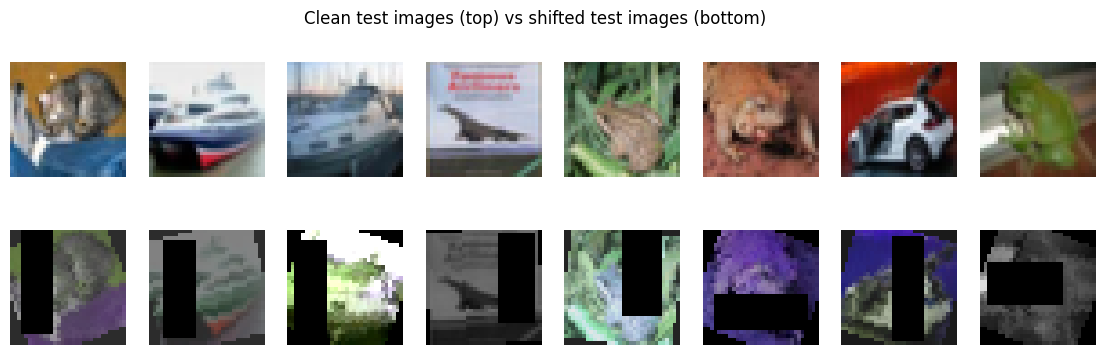

In [3]:
def hidden_corruption(img, r):
    # placeholder: random grayscale or channel swap
    if r.random() < 0.5:
        return TF.rgb_to_grayscale(img, num_output_channels=3)
    order = [0, 1, 2]
    r.shuffle(order)
    return img[order]

def occlude(img, r):
    # black rectangle covering about 25% of the image (256 of 1024 pixels)
    h = r.randint(8, 32)
    w = min(32, round(256 / h))
    top = r.randint(0, 32 - h)
    left = r.randint(0, 32 - w)
    img = img.clone()
    img[:, top:top + h, left:left + w] = 0
    return img

def make_shifted(X, seed):
    r = random.Random(seed)
    result = []
    for img in X:
        img = TF.rotate(img, r.uniform(-25, 25))
        img = TF.adjust_brightness(img, r.uniform(0.4, 1.6))
        img = TF.adjust_contrast(img, r.uniform(0.5, 1.5))
        img = hidden_corruption(img, r)
        img = occlude(img, r)
        result.append(img.clamp(0, 1))
    return torch.stack(result)

X_shift = make_shifted(X_clean, SHIFT_SEED)
y_shift = y_clean

# quick look: clean on top, shifted on the bottom
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i in range(8):
    axes[0, i].imshow(X_clean[i].permute(1, 2, 0))
    axes[0, i].axis("off")
    axes[1, i].imshow(X_shift[i].permute(1, 2, 0))
    axes[1, i].axis("off")
fig.suptitle("Clean test images (top) vs shifted test images (bottom)")
plt.show()

In [4]:
def conv_block(in_ch, out_ch, k, use_bn):
    layers = [nn.Conv2d(in_ch, out_ch, k, padding=k // 2)]
    if use_bn:
        layers.append(nn.BatchNorm2d(out_ch))
    layers.append(nn.ReLU())
    return nn.Sequential(*layers)


class InceptionBlock(nn.Module):
    def __init__(self, in_ch, n1, n3_reduce, n3, n5_reduce, n5, n_pool, use_bn):
        super().__init__()
        # branch 1: just a 1x1 conv
        self.branch1 = conv_block(in_ch, n1, 1, use_bn)
        # branch 2: 1x1 reduction then 3x3
        self.branch2 = nn.Sequential(
            conv_block(in_ch, n3_reduce, 1, use_bn),
            conv_block(n3_reduce, n3, 3, use_bn))
        # branch 3: 1x1 reduction then 5x5
        self.branch3 = nn.Sequential(
            conv_block(in_ch, n5_reduce, 1, use_bn),
            conv_block(n5_reduce, n5, 5, use_bn))
        # branch 4: max pool then 1x1
        self.branch4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            conv_block(in_ch, n_pool, 1, use_bn))

    def forward(self, x):
        out1 = self.branch1(x)
        out2 = self.branch2(x)
        out3 = self.branch3(x)
        out4 = self.branch4(x)
        return torch.cat([out1, out2, out3, out4], dim=1)


class Net(nn.Module):
    def __init__(self, mean, std, use_bn=False, drop=0.0):
        super().__init__()
        # normalization happens inside the model so augmentation can work on raw [0,1] pixels
        self.register_buffer("mean", mean.view(1, 3, 1, 1))
        self.register_buffer("std", std.view(1, 3, 1, 1))

        self.features = nn.Sequential(
            conv_block(3, 32, 3, use_bn),
            nn.MaxPool2d(2),                                    # 32 -> 16
            InceptionBlock(32, 16, 16, 24, 8, 8, 8, use_bn),    # outputs 16+24+8+8 = 56 channels
            nn.MaxPool2d(2),                                    # 16 -> 8
            conv_block(56, 96, 3, use_bn),
            nn.MaxPool2d(2),                                    # 8 -> 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(96 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(drop),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        x = (x - self.mean) / self.std
        x = self.features(x)
        return self.classifier(x)


# mean/std from the 400 training images only
pixel_mean = X_train.mean(dim=(0, 2, 3))
pixel_std = X_train.std(dim=(0, 2, 3))

test_model = Net(pixel_mean, pixel_std)
n_params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)
print("trainable parameters:", n_params, "(limit is 1,000,000)")

trainable parameters: 254074 (limit is 1,000,000)


In [5]:
def get_accuracy(model, X, y):
    model.eval()
    correct = 0
    with torch.no_grad():
        for i in range(0, len(X), 1000):
            xb = X[i:i + 1000].to(device)
            preds = model(xb).argmax(dim=1).cpu()
            correct += (preds == y[i:i + 1000]).sum().item()
    return 100 * correct / len(X)


def train_model(seed, augment=None, epochs=60, lr=1e-3, weight_decay=0.0,
                batch_size=64, use_bn=False, drop=0.0):
    set_seed(seed)
    model = Net(pixel_mean, pixel_std, use_bn=use_bn, drop=drop).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    Xtr = X_train.to(device)
    ytr = y_train.to(device)
    Xv = X_val.to(device)
    yv = y_val.to(device)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(Xtr), device=device)

        for i in range(0, len(Xtr), batch_size):
            batch_idx = order[i:i + batch_size]
            xb = Xtr[batch_idx]
            yb = ytr[batch_idx]

            if augment is not None:
                xb = augment(xb)      # only applied to training batches

            loss = F.cross_entropy(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # record metrics at the end of each epoch
        model.eval()
        with torch.no_grad():
            train_loss = F.cross_entropy(model(Xtr), ytr).item()
            val_loss = F.cross_entropy(model(Xv), yv).item()
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(get_accuracy(model, X_train, y_train))
        history["val_acc"].append(get_accuracy(model, X_val, y_val))

    results = {
        "train": history["train_acc"][-1],
        "val": history["val_acc"][-1],
        "clean": get_accuracy(model, X_clean, y_clean),
        "shifted": get_accuracy(model, X_shift, y_shift),
    }
    return model, history, results

In [8]:
baseline_histories = []
baseline_results = []

for seed in SEEDS:
    model, history, results = train_model(seed)
    baseline_histories.append(history)
    baseline_results.append(results)
    print("seed", seed, results)

print("\nBaseline (mean ± std over 3 seeds)")
for name in ["train", "val", "clean", "shifted"]:
    values = np.array([r[name] for r in baseline_results])
    print(f"{name:8s} {values.mean():.2f} ± {values.std():.2f}")

seed 0 {'train': 100.0, 'val': 46.0, 'clean': 37.43, 'shifted': 14.9}
seed 1 {'train': 100.0, 'val': 45.0, 'clean': 36.8, 'shifted': 13.67}
seed 2 {'train': 100.0, 'val': 45.0, 'clean': 38.34, 'shifted': 13.94}

Baseline (mean ± std over 3 seeds)
train    100.00 ± 0.00
val      45.33 ± 0.47
clean    37.52 ± 0.63
shifted  14.17 ± 0.53


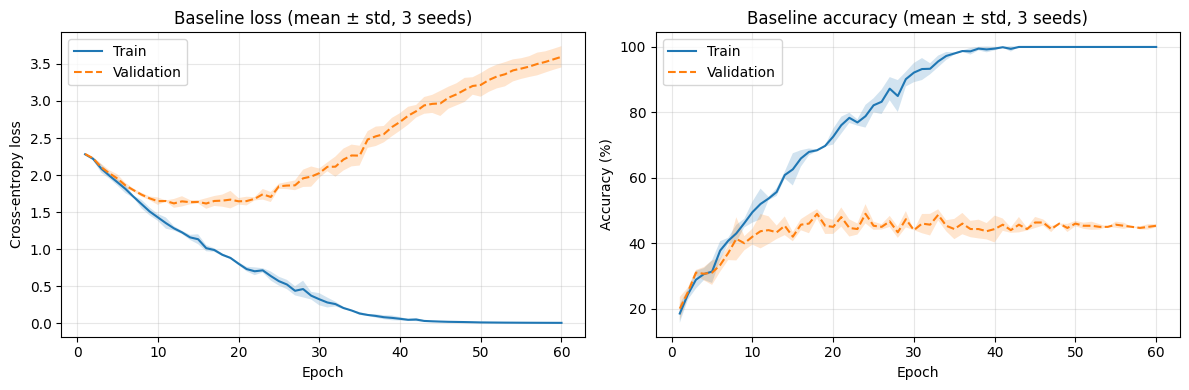

In [9]:
def plot_curves(ax, histories, keys, labels, title, ylabel):
    epochs = np.arange(1, 61)
    for key, label, style in zip(keys, labels, ["-", "--"]):
        data = np.array([h[key] for h in histories])
        avg = data.mean(axis=0)
        spread = data.std(axis=0)
        ax.plot(epochs, avg, style, label=label)
        ax.fill_between(epochs, avg - spread, avg + spread, alpha=0.2)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_curves(axes[0], baseline_histories, ["train_loss", "val_loss"],
            ["Train", "Validation"], "Baseline loss (mean ± std, 3 seeds)", "Cross-entropy loss")
plot_curves(axes[1], baseline_histories, ["train_acc", "val_acc"],
            ["Train", "Validation"], "Baseline accuracy (mean ± std, 3 seeds)", "Accuracy (%)")
plt.tight_layout()
plt.show()

# Part B

In [10]:
def geometric_aug(x, max_angle=20, max_shift=0.1, scale_low=0.9, scale_high=1.1):
    n = x.shape[0]
    dev = x.device

    # random angle, scale and shift for every image in the batch
    angle = (torch.rand(n, device=dev) * 2 - 1) * max_angle * np.pi / 180
    scale = torch.empty(n, device=dev).uniform_(scale_low, scale_high)
    shift_x = (torch.rand(n, device=dev) * 2 - 1) * max_shift * 2   # coords go from -1 to 1
    shift_y = (torch.rand(n, device=dev) * 2 - 1) * max_shift * 2

    cos = torch.cos(angle) / scale
    sin = torch.sin(angle) / scale

    theta = torch.zeros(n, 2, 3, device=dev)
    theta[:, 0, 0] = cos
    theta[:, 0, 1] = -sin
    theta[:, 0, 2] = shift_x
    theta[:, 1, 0] = sin
    theta[:, 1, 1] = cos
    theta[:, 1, 2] = shift_y

    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)

    # horizontal flip for about half of the images
    flip_mask = torch.rand(n, device=dev) < 0.5
    x = torch.where(flip_mask.view(-1, 1, 1, 1), x.flip(3), x)
    return x

In [11]:
def photometric_aug(x, blur_prob=0.3, max_noise=0.06):
    n = x.shape[0]
    dev = x.device

    # brightness: multiply every pixel
    brightness = torch.empty(n, 1, 1, 1, device=dev).uniform_(0.6, 1.4)
    x = x * brightness

    # contrast: push pixels away from or toward the image mean
    contrast = torch.empty(n, 1, 1, 1, device=dev).uniform_(0.6, 1.4)
    img_mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - img_mean) * contrast + img_mean

    # saturation: push colors away from or toward the gray version
    saturation = torch.empty(n, 1, 1, 1, device=dev).uniform_(0.6, 1.4)
    gray = x.mean(dim=1, keepdim=True)
    x = (x - gray) * saturation + gray

    # blur: a small 3x3 kernel, applied to some of the images only
    kernel = torch.tensor([[1., 2., 1.],
                           [2., 4., 2.],
                           [1., 2., 1.]], device=dev) / 16
    kernel = kernel.view(1, 1, 3, 3).repeat(3, 1, 1, 1)
    blurred = F.conv2d(F.pad(x, (1, 1, 1, 1), mode="reflect"), kernel, groups=3)
    blur_mask = torch.rand(n, device=dev) < blur_prob
    x = torch.where(blur_mask.view(-1, 1, 1, 1), blurred, x)

    # gaussian noise with a random strength per image
    noise_std = torch.rand(n, 1, 1, 1, device=dev) * max_noise
    x = x + torch.randn_like(x) * noise_std

    return x.clamp(0, 1)

In [12]:
def cutout(x, size=14):
    n, c, h, w = x.shape
    dev = x.device

    # random center of the square for each image
    cy = torch.randint(0, h, (n, 1, 1), device=dev)
    cx = torch.randint(0, w, (n, 1, 1), device=dev)

    rows = torch.arange(h, device=dev).view(1, h, 1)
    cols = torch.arange(w, device=dev).view(1, 1, w)

    inside_rows = (rows >= cy - size // 2) & (rows < cy + size // 2)
    inside_cols = (cols >= cx - size // 2) & (cols < cx + size // 2)
    hole = (inside_rows & inside_cols).unsqueeze(1)    # shape (n, 1, h, w)

    return x.masked_fill(hole, 0.0)

In [13]:
def make_augment(geometric=False, photometric=False, use_cutout=False):
    def augment(x):
        if geometric:
            x = geometric_aug(x)
        if photometric:
            x = photometric_aug(x)
        if use_cutout:
            x = cutout(x)
        return x
    return augment

In [14]:
def train_model(seed, augment=None, epochs=60, lr=1e-3, weight_decay=0.0,
                batch_size=64, use_bn=False, drop=0.0,
                mixup_alpha=0.0, label_smoothing=0.0, eval_test=True):
    set_seed(seed)
    model = Net(pixel_mean, pixel_std, use_bn=use_bn, drop=drop).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    Xtr = X_train.to(device)
    ytr = y_train.to(device)
    Xv = X_val.to(device)
    yv = y_val.to(device)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(Xtr), device=device)

        for i in range(0, len(Xtr), batch_size):
            batch_idx = order[i:i + batch_size]
            xb = Xtr[batch_idx]
            yb = ytr[batch_idx]

            if augment is not None:
                xb = augment(xb)

            if mixup_alpha > 0:
                # blend each image with another image from the same batch
                lam = np.random.beta(mixup_alpha, mixup_alpha)
                other = torch.randperm(len(xb), device=device)
                xb = lam * xb + (1 - lam) * xb[other]
                out = model(xb)
                loss = lam * F.cross_entropy(out, yb, label_smoothing=label_smoothing) \
                     + (1 - lam) * F.cross_entropy(out, yb[other], label_smoothing=label_smoothing)
            else:
                out = model(xb)
                loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        # logging uses plain cross-entropy so the curves are comparable between runs
        model.eval()
        with torch.no_grad():
            train_loss = F.cross_entropy(model(Xtr), ytr).item()
            val_loss = F.cross_entropy(model(Xv), yv).item()
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(get_accuracy(model, X_train, y_train))
        history["val_acc"].append(get_accuracy(model, X_val, y_val))

    results = {"train": history["train_acc"][-1], "val": history["val_acc"][-1]}
    if eval_test:
        results["clean"] = get_accuracy(model, X_clean, y_clean)
        results["shifted"] = get_accuracy(model, X_shift, y_shift)
    return model, history, results

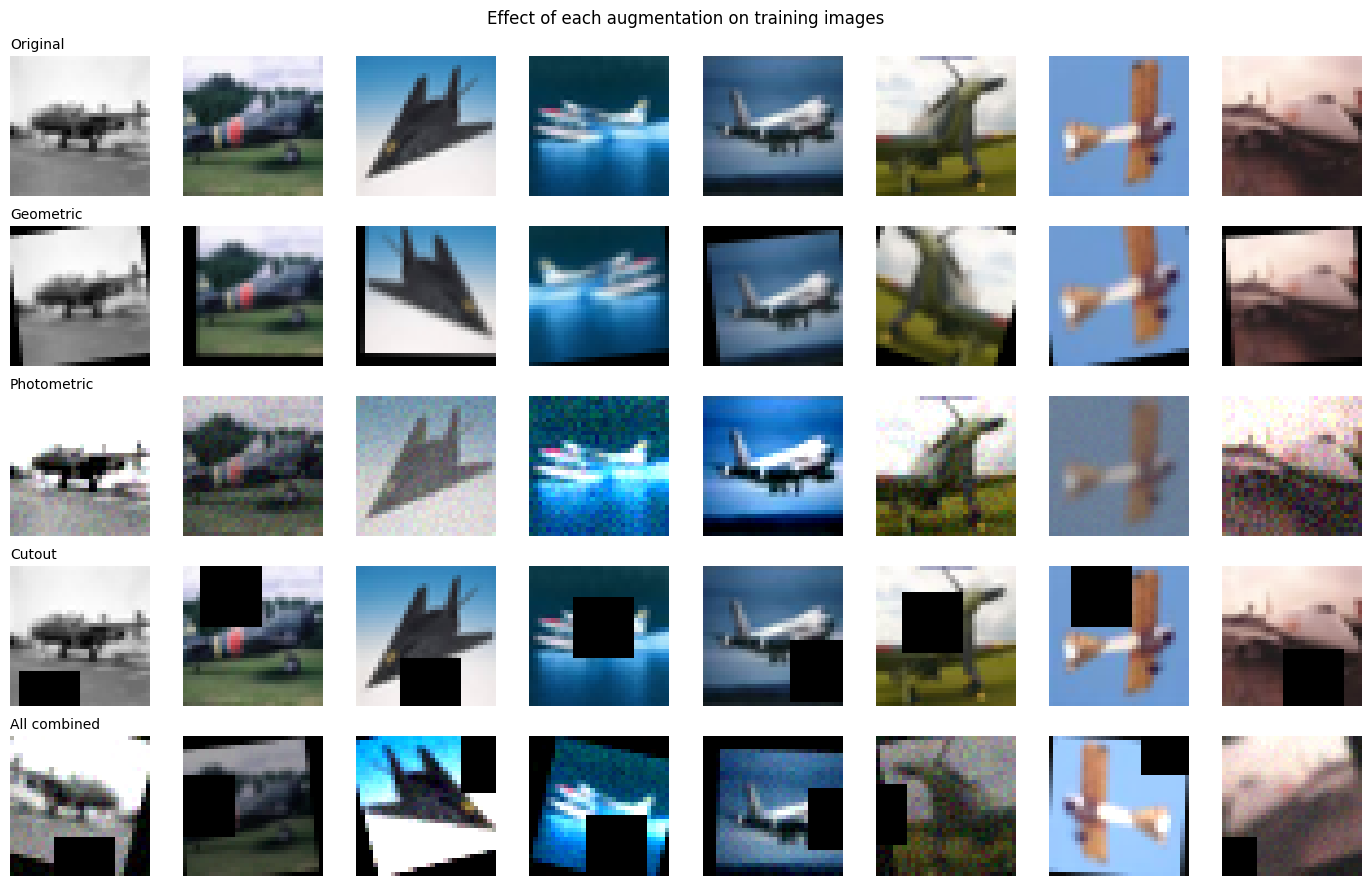

In [15]:
sample = X_train[:8].to(device)
versions = [
    ("Original", sample),
    ("Geometric", geometric_aug(sample)),
    ("Photometric", photometric_aug(sample)),
    ("Cutout", cutout(sample)),
    ("All combined", make_augment(True, True, True)(sample)),
]

fig, axes = plt.subplots(len(versions), 8, figsize=(14, 9))
for row, (name, imgs) in enumerate(versions):
    for col in range(8):
        axes[row, col].imshow(imgs[col].cpu().permute(1, 2, 0))
        axes[row, col].axis("off")
    axes[row, 0].set_title(name, loc="left", fontsize=10)
plt.suptitle("Effect of each augmentation on training images")
plt.tight_layout()
plt.show()

In [16]:
configs = {
    "none": make_augment(False, False, False),
    "geometric": make_augment(True, False, False),
    "photometric": make_augment(False, True, False),
    "geo + photo": make_augment(True, True, False),
    "geo + photo + cutout": make_augment(True, True, True),
}

for name, aug in configs.items():
    _, _, res = train_model(seed=0, augment=aug, eval_test=False)
    print(f"{name:22s} val acc: {res['val']:.1f}")

none                   val acc: 46.0
geometric              val acc: 42.0
photometric            val acc: 38.0
geo + photo            val acc: 46.0
geo + photo + cutout   val acc: 43.0


# part c

In [19]:
def make_val_shifted(X, seed=777):
    r = random.Random(seed)
    result = []
    for img in X:
        img = TF.rotate(img, r.uniform(-25, 25))
        img = TF.adjust_brightness(img, r.uniform(0.4, 1.6))
        img = TF.adjust_contrast(img, r.uniform(0.5, 1.5))
        img = occlude(img, r)
        result.append(img.clamp(0, 1))
    return torch.stack(result)

X_val_shift = make_val_shifted(X_val)
print(X_val_shift.shape)   # should be torch.Size([100, 3, 32, 32])

torch.Size([100, 3, 32, 32])


In [20]:
import copy

def train_model(seed, augment=None, epochs=60, lr=1e-3, weight_decay=0.0,
                batch_size=32, use_bn=False, drop=0.0,
                mixup_alpha=0.0, label_smoothing=0.0,
                use_schedule=False, patience=None, eval_test=True):
    set_seed(seed)
    model = Net(pixel_mean, pixel_std, use_bn=use_bn, drop=drop).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    scheduler = None
    if use_schedule:
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    Xtr = X_train.to(device)
    ytr = y_train.to(device)
    Xv = X_val.to(device)
    yv = y_val.to(device)

    history = {"train_loss": [], "val_loss": [], "train_acc": [],
               "val_acc": [], "val_shift_acc": []}

    best_score = -1
    best_weights = None
    best_epoch = 0
    bad_epochs = 0

    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(Xtr), device=device)

        for i in range(0, len(Xtr), batch_size):
            batch_idx = order[i:i + batch_size]
            if len(batch_idx) < 2:
                continue          # BatchNorm cannot handle a batch of 1
            xb = Xtr[batch_idx]
            yb = ytr[batch_idx]

            if augment is not None:
                xb = augment(xb)

            if mixup_alpha > 0:
                lam = np.random.beta(mixup_alpha, mixup_alpha)
                other = torch.randperm(len(xb), device=device)
                xb = lam * xb + (1 - lam) * xb[other]
                out = model(xb)
                loss = lam * F.cross_entropy(out, yb, label_smoothing=label_smoothing) \
                     + (1 - lam) * F.cross_entropy(out, yb[other], label_smoothing=label_smoothing)
            else:
                out = model(xb)
                loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        if scheduler is not None:
            scheduler.step()

        # end of epoch: record metrics
        model.eval()
        with torch.no_grad():
            train_loss = F.cross_entropy(model(Xtr), ytr).item()
            val_loss = F.cross_entropy(model(Xv), yv).item()
        train_acc = get_accuracy(model, X_train, y_train)
        val_acc = get_accuracy(model, X_val, y_val)
        val_shift_acc = get_accuracy(model, X_val_shift, y_val)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["val_shift_acc"].append(val_shift_acc)

        # early stopping score: average of clean and shifted validation accuracy
        score = (val_acc + val_shift_acc) / 2
        if score > best_score:
            best_score = score
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1

        if patience is not None and bad_epochs >= patience:
            break

    # go back to the best epoch if early stopping is on
    if patience is not None:
        model.load_state_dict(best_weights)

    results = {
        "train": get_accuracy(model, X_train, y_train),
        "val": get_accuracy(model, X_val, y_val),
        "val_shift": get_accuracy(model, X_val_shift, y_val),
        "best_epoch": best_epoch + 1,
    }
    if eval_test:
        results["clean"] = get_accuracy(model, X_clean, y_clean)
        results["shifted"] = get_accuracy(model, X_shift, y_shift)
    return model, history, results

In [ ]:
aug = make_augment(True, True, True)

def score_setting(**kwargs):
    clean_scores = []
    shift_scores = []
    for seed in SEEDS:
        _, _, res = train_model(seed, augment=aug, eval_test=False, **kwargs)
        clean_scores.append(res["val"])
        shift_scores.append(res["val_shift"])
    return np.mean(clean_scores), np.mean(shift_scores)

def pick_best(step_name, options, base):
    # options: dict of  label -> settings to change.  base: settings from earlier steps
    print("\n" + step_name)
    best_label = None
    best_score = -1
    for label, change in options.items():
        settings = dict(base)
        settings.update(change)
        clean, shifted = score_setting(**settings)
        avg = (clean + shifted) / 2
        print(f"  {label:28s} val clean {clean:5.1f}   val shifted {shifted:5.1f}")
        if avg > best_score:
            best_score = avg
            best_label = label
            best_change = change
    print("  -> winner:", best_label)
    base.update(best_change)
    return base

base = {}
base = pick_best("Step 1: BatchNorm", {
    "no BN": {"use_bn": False},
    "BN": {"use_bn": True}}, base)

base = pick_best("Step 2: Dropout", {
    "dropout 0.0": {"drop": 0.0},
    "dropout 0.3": {"drop": 0.3},
    "dropout 0.5": {"drop": 0.5}}, base)

base = pick_best("Step 3: Weight decay", {
    "wd 0": {"weight_decay": 0.0},
    "wd 1e-3": {"weight_decay": 1e-3},
    "wd 1e-2": {"weight_decay": 1e-2},
    "wd 5e-2": {"weight_decay": 5e-2}}, base)

base = pick_best("Step 4: LR schedule", {
    "constant lr 1e-3": {"use_schedule": False, "lr": 1e-3},
    "cosine lr 1e-3": {"use_schedule": True, "lr": 1e-3},
    "cosine lr 3e-3": {"use_schedule": True, "lr": 3e-3}}, base)

base = pick_best("Step 5: Label smoothing", {
    "smoothing 0.0": {"label_smoothing": 0.0},
    "smoothing 0.1": {"label_smoothing": 0.1},
    "smoothing 0.2": {"label_smoothing": 0.2}}, base)

base = pick_best("Step 6: Early stopping", {
    "no early stopping": {"patience": None},
    "patience 15": {"patience": 15}}, base)

print("\nFinal settings:", base)


Step 1: BatchNorm
  no BN                        val clean  40.3   val shifted  35.7
  BN                           val clean  46.7   val shifted  39.0
  -> winner: BN

Step 2: Dropout
  dropout 0.0                  val clean  46.7   val shifted  39.0
  dropout 0.3                  val clean  45.0   val shifted  41.3
  dropout 0.5                  val clean  36.0   val shifted  34.0
  -> winner: dropout 0.3

Step 3: Weight decay
  wd 0                         val clean  45.0   val shifted  41.3
  wd 1e-3                      val clean  50.7   val shifted  42.0
  wd 1e-2                      val clean  49.7   val shifted  40.3
  wd 5e-2                      val clean  48.7   val shifted  41.7
  -> winner: wd 1e-3

Step 4: LR schedule
  constant lr 1e-3             val clean  50.7   val shifted  42.0
  cosine lr 1e-3               val clean  47.0   val shifted  45.7
  cosine lr 3e-3               val clean  40.0   val shifted  41.0
  -> winner: constant lr 1e-3

Step 5: Label smoothing


In [ ]:
# step 4: lr schedule and learning rate
try_setting("constant lr 1e-3", use_bn=True, drop=0.3, weight_decay=1e-2)
try_setting("cosine lr 1e-3", use_bn=True, drop=0.3, weight_decay=1e-2, use_schedule=True)
try_setting("cosine lr 3e-3", use_bn=True, drop=0.3, weight_decay=1e-2, use_schedule=True, lr=3e-3)

# step 5: label smoothing
for ls in [0.0, 0.1, 0.2]:
    try_setting(f"label smoothing {ls}", use_bn=True, drop=0.3, weight_decay=1e-2,
                use_schedule=True, label_smoothing=ls)

# step 6: early stopping
try_setting("early stopping (patience 15)", use_bn=True, drop=0.3, weight_decay=1e-2,
            use_schedule=True, label_smoothing=0.1, patience=15)

# Part D

In [ ]:
# regularization settings from tuning, minus the parts we switch on row by row
common = dict(base)
common.pop("label_smoothing", None)
common.pop("patience", None)

final_patience = base.get("patience", None)

ablation = [
    ("No augmentation",        make_augment(False, False, False), {}),
    ("Geometric only",         make_augment(True, False, False),  {}),
    ("Photometric only",       make_augment(False, True, False),  {}),
    ("Geometric + photometric", make_augment(True, True, False),  {}),
    ("+ Cutout",               make_augment(True, True, True),    {}),
    ("+ Mixup + label smoothing", make_augment(True, True, True),
        {"mixup_alpha": 0.4, "label_smoothing": 0.1}),
    ("Final model",            make_augment(True, True, True),
        {"mixup_alpha": 0.4, "label_smoothing": 0.1, "patience": final_patience}),
]

ablation_results = {}
final_models = []
final_histories = []

for name, aug, extra in ablation:
    settings = dict(common)
    settings.update(extra)
    runs = []
    for seed in SEEDS:
        model, history, res = train_model(seed, augment=aug, **settings)
        runs.append(res)
        if name == "Final model":
            final_models.append(model)
            final_histories.append(history)
    ablation_results[name] = runs
    print("finished:", name)

In [ ]:
print(f"{'Configuration':28s} {'Val Acc':>14s} {'Clean Test':>14s} {'Shifted Test':>14s}")
print("-" * 74)

for name, runs in ablation_results.items():
    line = f"{name:28s}"
    for key in ["val", "clean", "shifted"]:
        values = np.array([r[key] for r in runs])
        line += f" {values.mean():6.2f} ± {values.std():4.2f}"
    print(line)

In [ ]:
names = list(ablation_results.keys())
shift_means = []
shift_stds = []
clean_means = []
for name in names:
    shifted = np.array([r["shifted"] for r in ablation_results[name]])
    clean = np.array([r["clean"] for r in ablation_results[name]])
    shift_means.append(shifted.mean())
    shift_stds.append(shifted.std())
    clean_means.append(clean.mean())

x = np.arange(len(names))
plt.figure(figsize=(11, 5))
plt.bar(x - 0.2, clean_means, width=0.4, label="Clean test")
plt.bar(x + 0.2, shift_means, width=0.4, yerr=shift_stds, capsize=3, label="Shifted test")
plt.xticks(x, names, rotation=30, ha="right")
plt.ylabel("Accuracy (%)")
plt.title("Ablation: accuracy per configuration (mean ± std, 3 seeds)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nGain on shifted test compared with the row above:")
for i in range(1, len(names)):
    gain = shift_means[i] - shift_means[i - 1]
    print(f"  {names[i]:28s} {gain:+.2f}")
print("\nGain of each single augmentation over no augmentation:")
for i in [1, 2]:
    print(f"  {names[i]:28s} {shift_means[i] - shift_means[0]:+.2f}")

# Part E

In [ ]:
class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

def get_predictions(model, X):
    model.eval()
    all_preds = []
    all_probs = []
    with torch.no_grad():
        for i in range(0, len(X), 1000):
            out = model(X[i:i + 1000].to(device))
            probs = F.softmax(out, dim=1)
            all_preds.append(probs.argmax(dim=1).cpu())
            all_probs.append(probs.cpu())
    return torch.cat(all_preds), torch.cat(all_probs)

model0 = final_models[0]
preds, probs = get_predictions(model0, X_shift)

print("Per-class accuracy on shifted test (final model, seed 0)")
for c in range(10):
    mask = (y_shift == c)
    acc = 100 * (preds[mask] == c).float().mean().item()
    print(f"  {class_names[c]:12s} {acc:5.1f}%")

In [ ]:
matrix = np.zeros((10, 10))
for true_label, pred_label in zip(y_shift.numpy(), preds.numpy()):
    matrix[true_label, pred_label] += 1

# divide each row by its total so every row sums to 1
matrix_norm = matrix / matrix.sum(axis=1, keepdims=True)

plt.figure(figsize=(8, 7))
plt.imshow(matrix_norm, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Fraction of true class")
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
for i in range(10):
    for j in range(10):
        color = "white" if matrix_norm[i, j] > 0.5 else "black"
        plt.text(j, i, f"{matrix_norm[i, j]:.2f}", ha="center", va="center",
                 fontsize=7, color=color)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Normalized confusion matrix (shifted test, final model)")
plt.tight_layout()
plt.show()

In [ ]:
pairs = []
for i in range(10):
    for j in range(10):
        if i != j:
            pairs.append((matrix_norm[i, j], class_names[i], class_names[j]))
pairs.sort(reverse=True)

print("Top 6 confusions (true -> predicted):")
for value, true_name, pred_name in pairs[:6]:
    print(f"  {true_name:12s} -> {pred_name:12s} {100 * value:5.1f}% of {true_name} images")

In [ ]:
wrong = (preds != y_shift).nonzero().flatten().numpy()
chooser = np.random.RandomState(0)
chosen = chooser.choice(wrong, 12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(11, 9))
for ax, idx in zip(axes.flatten(), chosen):
    ax.imshow(X_shift[idx].permute(1, 2, 0))
    true_name = class_names[y_shift[idx]]
    pred_name = class_names[preds[idx]]
    confidence = 100 * probs[idx].max().item()
    ax.set_title(f"#{idx}\ntrue: {true_name}\npred: {pred_name} ({confidence:.0f}%)", fontsize=9)
    ax.axis("off")
fig.suptitle("Misclassified shifted-test images")
plt.tight_layout()
plt.show()

In [ ]:
def apply_hidden_only(X, seed):
    r = random.Random(seed)
    result = []
    for img in X:
        result.append(hidden_corruption(img, r).clamp(0, 1))
    return torch.stack(result)

X_hidden_only = apply_hidden_only(X_clean, SHIFT_SEED)

hidden_scores = []
clean_scores = []
for model in final_models:
    hidden_scores.append(get_accuracy(model, X_hidden_only, y_clean))
    clean_scores.append(get_accuracy(model, X_clean, y_clean))

hidden_scores = np.array(hidden_scores)
clean_scores = np.array(clean_scores)
print(f"clean test:            {clean_scores.mean():.2f} ± {clean_scores.std():.2f}")
print(f"hidden corruption only: {hidden_scores.mean():.2f} ± {hidden_scores.std():.2f}")
print(f"drop: {clean_scores.mean() - hidden_scores.mean():.2f} points")

# Part F

In [ ]:
import time

def shift_image(x, dx, dy):
    # move the image right by dx and down by dy, fill the gap with zeros
    pad = 4
    padded = F.pad(x, (pad, pad, pad, pad))
    h = x.shape[2]
    w = x.shape[3]
    top = pad - dy
    left = pad - dx
    return padded[:, :, top:top + h, left:left + w]

def make_views(n):
    views = [lambda x: x, lambda x: x.flip(3)]
    for dx, dy in [(2, 0), (-2, 0), (0, 2), (0, -2)]:
        views.append(lambda x, dx=dx, dy=dy: shift_image(x, dx, dy))
        views.append(lambda x, dx=dx, dy=dy: shift_image(x, dx, dy).flip(3))
    return views[:n]

def tta_accuracy(model, X, y, n_views):
    model.eval()
    views = make_views(n_views)
    correct = 0
    with torch.no_grad():
        for i in range(0, len(X), 500):
            xb = X[i:i + 500].to(device)
            total_probs = 0
            for view in views:
                total_probs = total_probs + F.softmax(model(view(xb)), dim=1)
            preds = total_probs.argmax(dim=1).cpu()
            correct += (preds == y[i:i + 500]).sum().item()
    return 100 * correct / len(X)

In [ ]:
n_options = [1, 2, 6, 10]
tta_table = {}

for n in n_options:
    accs = []
    times = []
    for model in final_models:
        if device == "cuda":
            torch.cuda.synchronize()
        start = time.time()
        acc = tta_accuracy(model, X_shift, y_shift, n)
        if device == "cuda":
            torch.cuda.synchronize()
        times.append(time.time() - start)
        accs.append(acc)
    tta_table[n] = (np.mean(accs), np.std(accs), np.mean(times))

base_acc = tta_table[1][0]
base_time = tta_table[1][2]

print(f"{'N views':8s} {'Shifted acc':>16s} {'Change':>9s} {'Time (s)':>10s} {'Cost':>7s}")
for n in n_options:
    mean_acc, std_acc, t = tta_table[n]
    print(f"{n:<8d} {mean_acc:7.2f} ± {std_acc:4.2f} {mean_acc - base_acc:+8.2f} "
          f"{t:10.2f} {t / base_time:6.1f}x")